In [ ]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from models.lstm import run_lstm
from utils.plots import plot_forecast

## Buscando dados

In [2]:
vale_csv = "data/vale.csv"
if not os.path.exists(vale_csv):
    vale3_dataset = load_stock(STOCKS["vale"], "vale", force=True)
    vale3_dataset.head(10)

vale3_dataset = pd.read_csv(vale_csv)

In [3]:
vale3_dataset

,date,vale_close,vale_high,vale_low,vale_open,vale_volume,ibovespa,vix,selic_daily,selic_goal,ipca,fx_usd,gdp,unemployment
0,2010-01-04,19.546474,19.546474,18.904921,19.052971,2381400,70045.0,20.040001,0.032927,8.75,0.75,1.7240,284387.8,NaN
1,2010-01-05,19.728697,19.945078,19.451577,19.565461,3001800,70240.0,19.350000,0.032927,8.75,0.75,1.7227,284387.8,NaN
2,2010-01-06,20.146273,20.260157,19.656566,19.740083,2742800,70729.0,19.160000,0.032927,8.75,0.75,1.7337,284387.8,NaN
3,2010-01-07,20.229794,20.324698,19.929896,19.933691,2543100,70451.0,19.059999,0.032927,8.75,0.75,1.7413,284387.8,NaN
4,2010-01-08,20.427189,20.590424,20.119699,20.233583,2444500,70263.0,18.129999,0.032927,8.75,0.75,1.7390,284387.8,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3969,2025-12-22,70.929672,71.367394,68.877263,69.091260,27853000,158142.0,14.080000,0.055131,15.00,0.33,5.5389,1084318.8,5.1
3970,2025-12-23,70.910225,71.523027,70.598959,71.231219,17140900,160456.0,14.000000,0.055131,15.00,0.33,5.5643,1084318.8,5.1
3971,2025-12-26,71.124222,71.347940,70.637869,70.871316,16368800,160897.0,13.600000,0.055131,15.00,0.33,5.5413,1084318.8,5.1
3972,2025-12-29,70.151512,71.727290,69.742970,71.192307,19963700,160490.0,14.200000,0.055131,15.00,0.33,5.5739,1084318.8,5.1


In [4]:
print(vale3_dataset.isna().sum())

date              0
vale_close        0
vale_high         0
vale_low          0
vale_open         0
vale_volume       0
ibovespa          0
vix               0
selic_daily       0
selic_goal        0
ipca              0
fx_usd            0
gdp               0
unemployment    535
dtype: int64


## ARIMA

In [5]:
train_vale, test_vale = split_temporal(vale3_dataset)
res_vale = run_arima(train_vale, test_vale, "vale")

--- Identificando ordem do ARIMA para VALE ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=6245.399, Time=1.10 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=6241.635, Time=0.12 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=6243.559, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=6243.556, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=6240.428, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=6243.877, Time=0.40 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 1.870 seconds
Ordem ARIMA selecionada: (0, 1, 0)
ARIMA(0, 1, 0) vale    RMSE: 0.8408 | MAE: 0.6054 | MAPE: 1.14% | Acurácia direcional: n/a


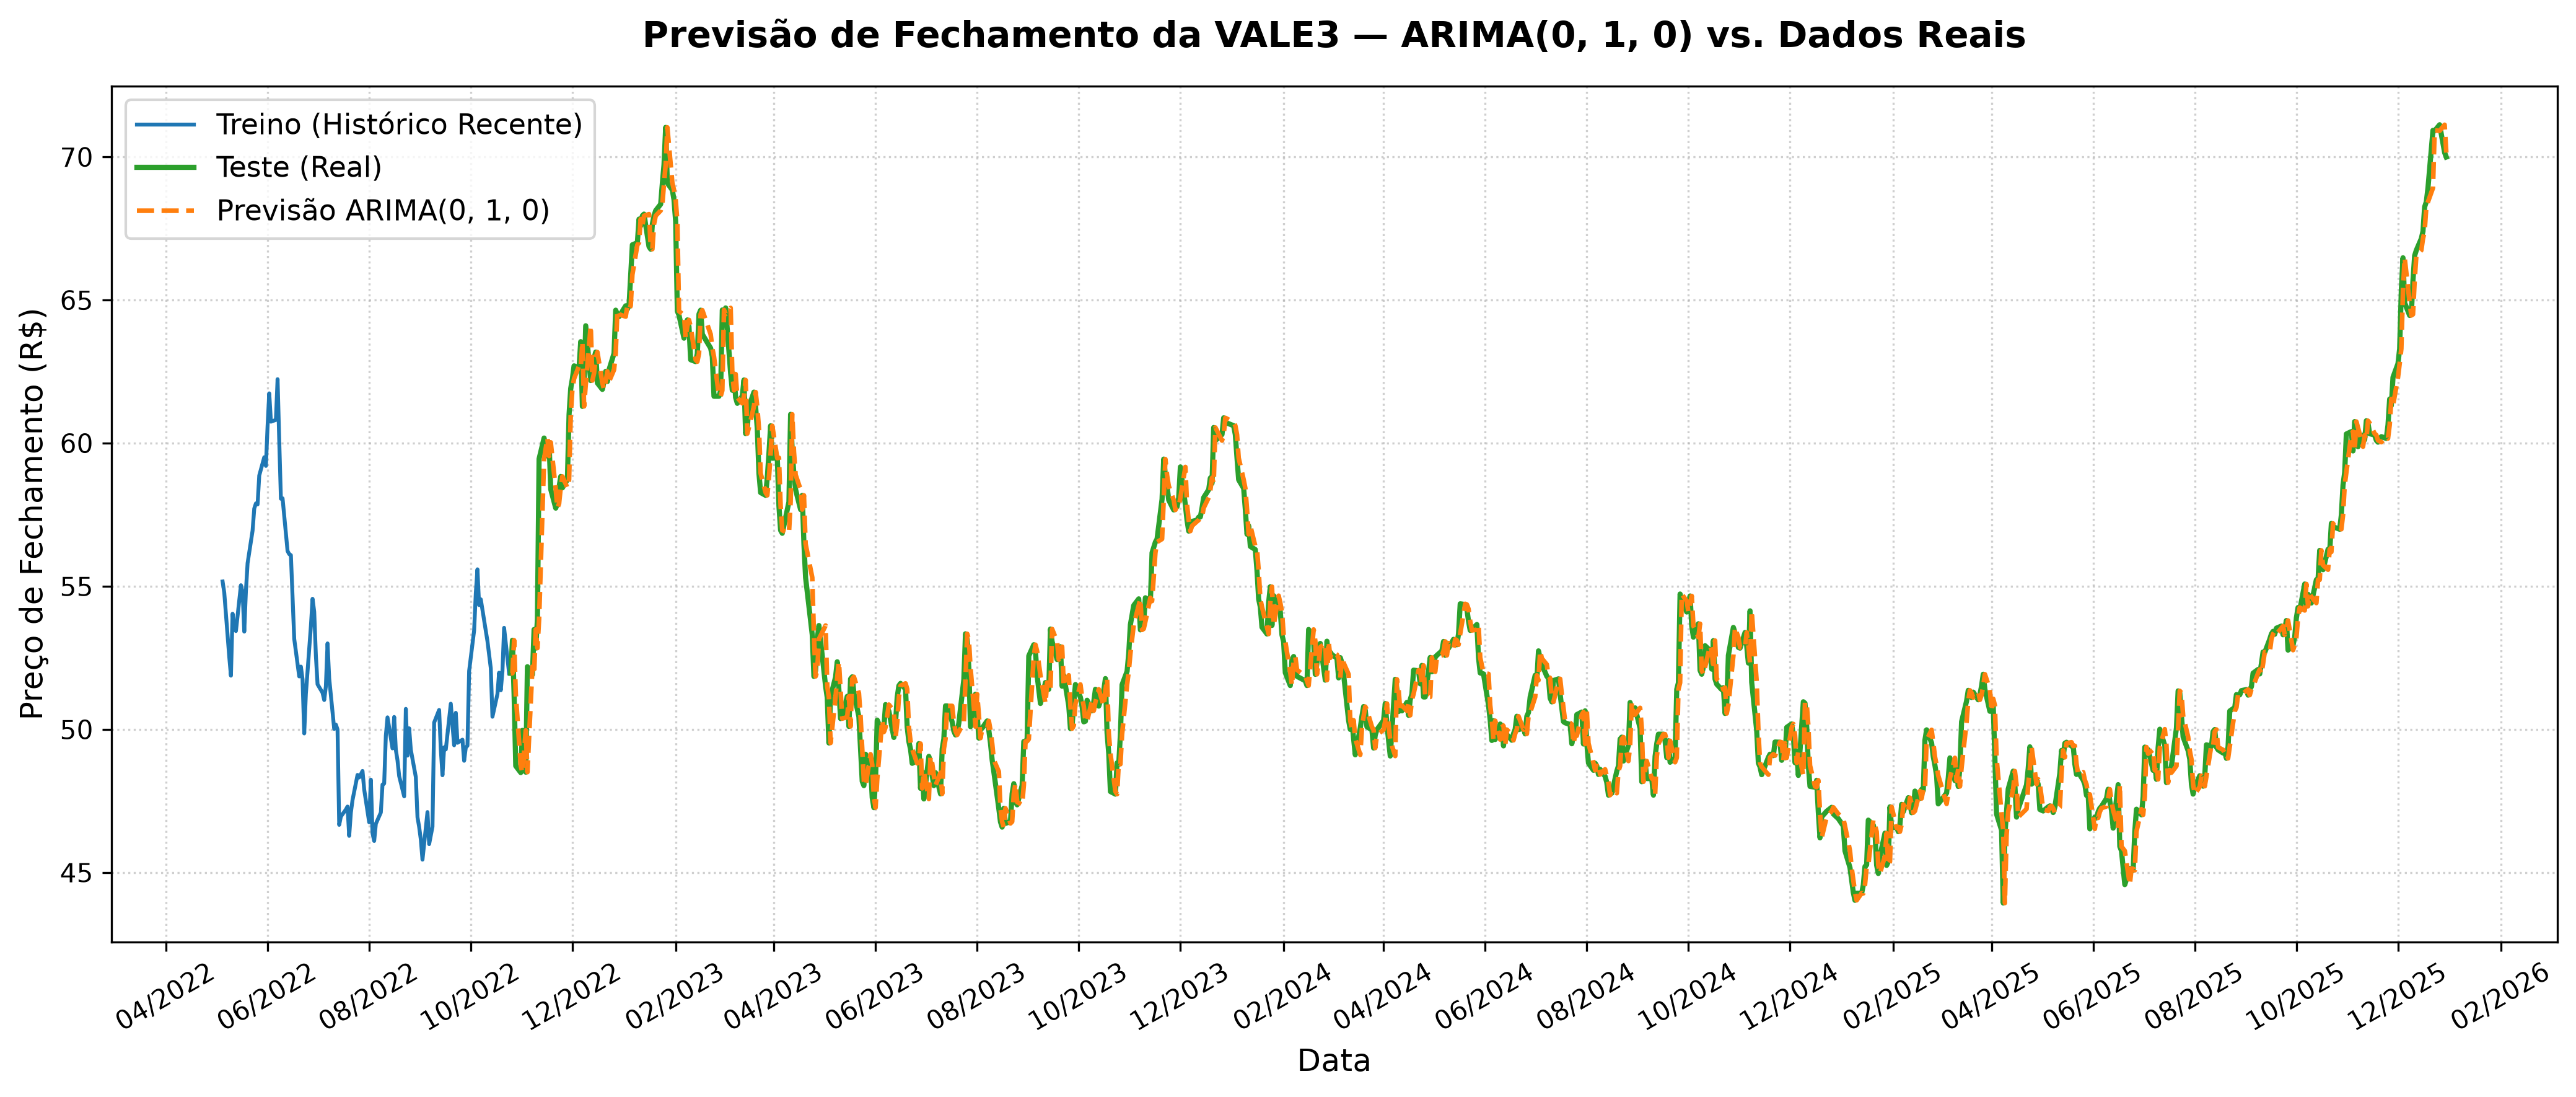

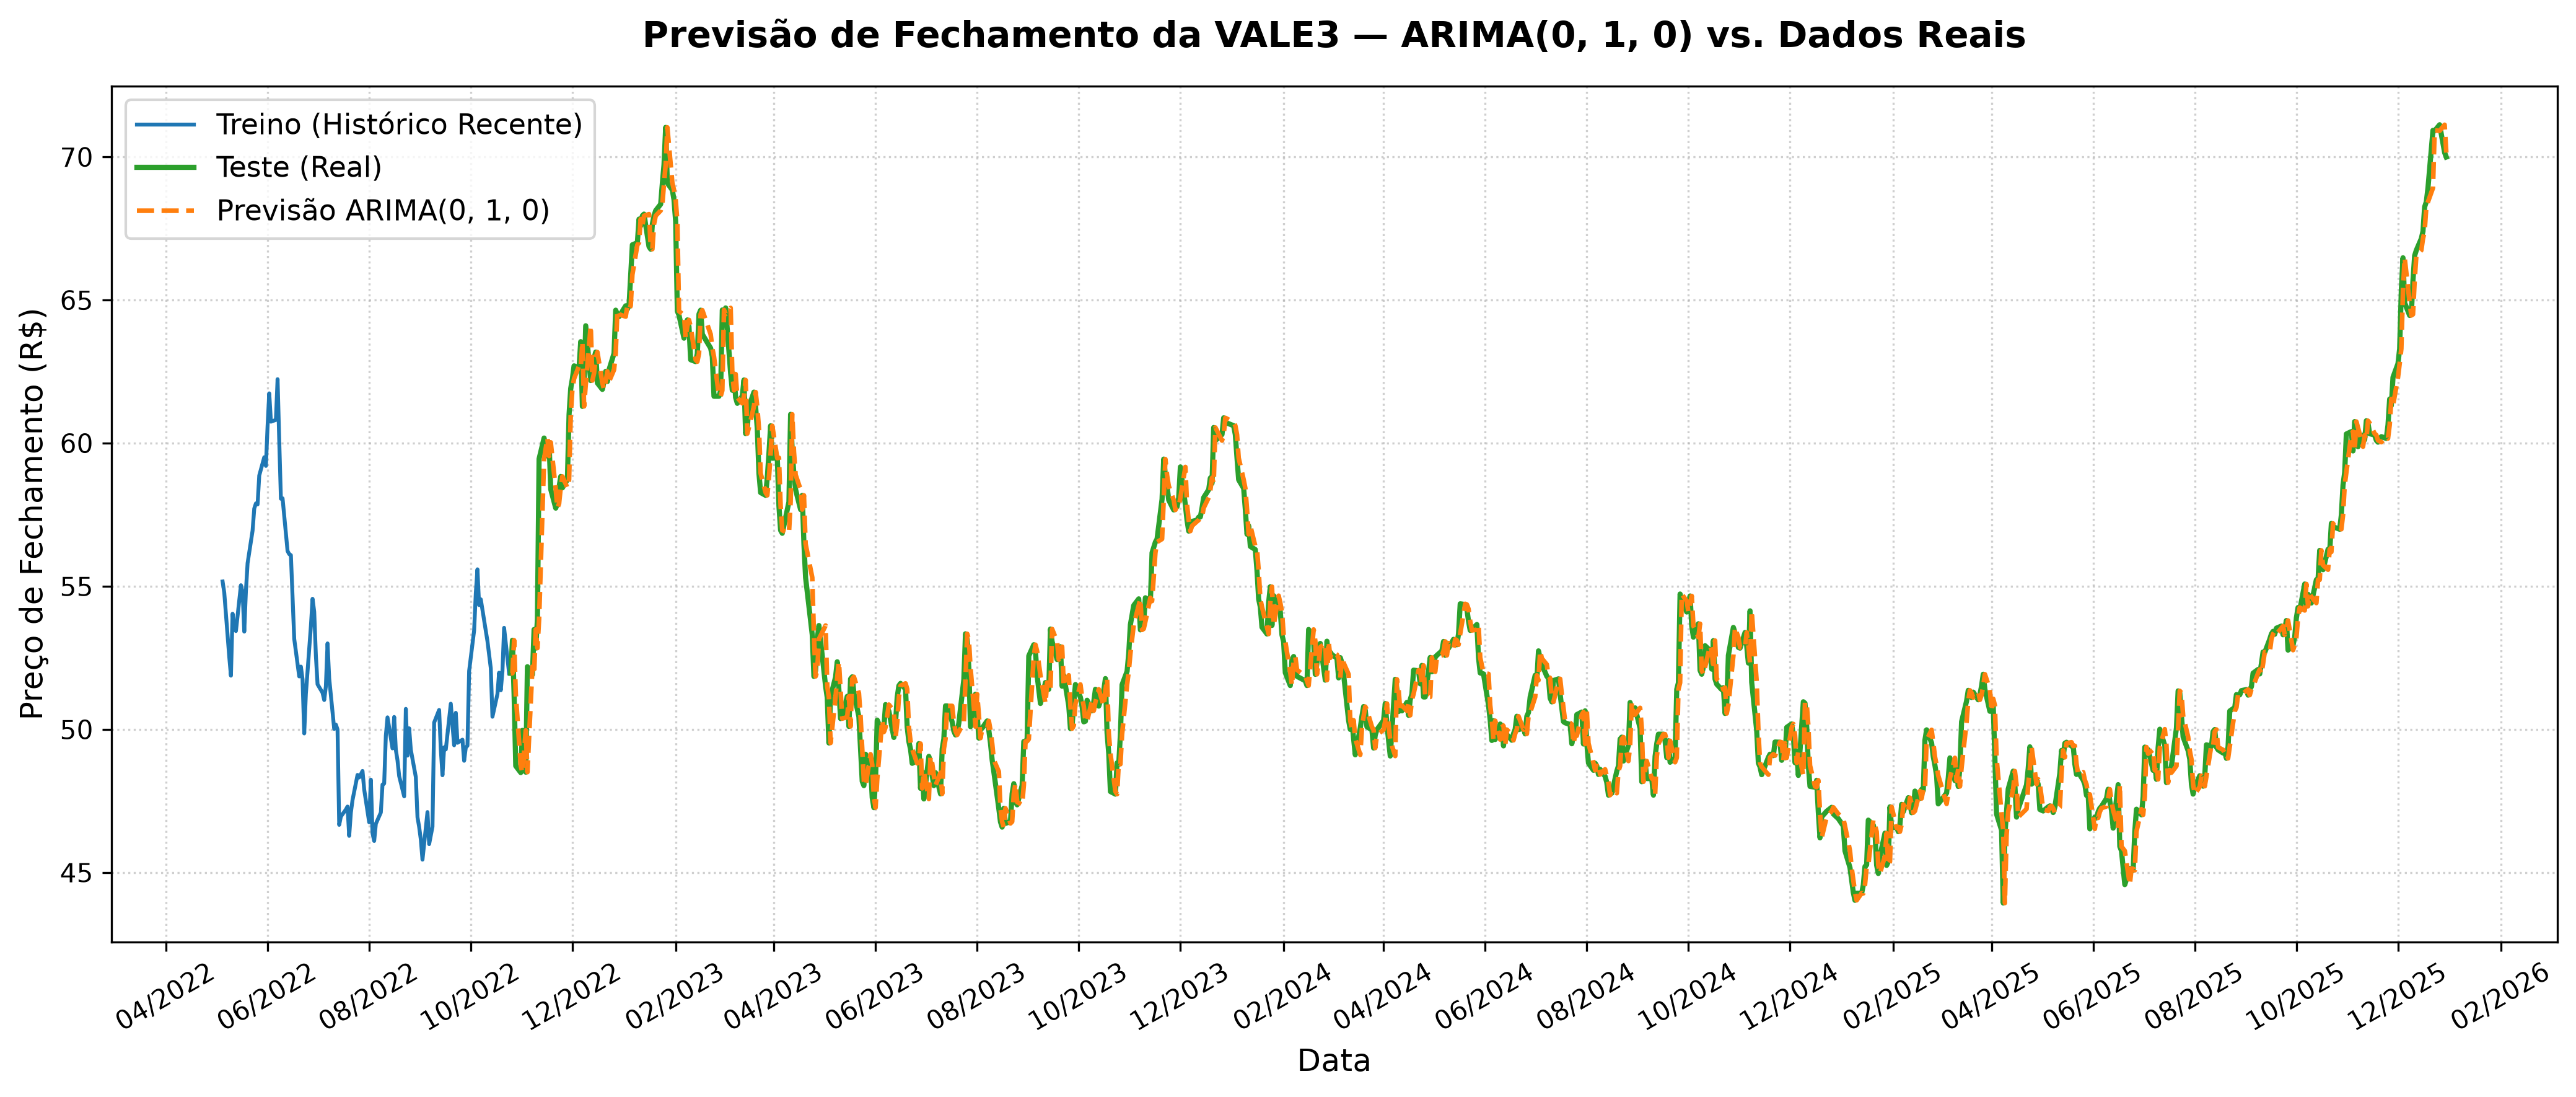

In [6]:
plot_forecast(
    train_vale, test_vale,
    predictions=res_vale["predictions"],
    stock_name="vale",
    model_name=f"ARIMA{res_vale['order']}",
    ticker_label="VALE3",
)

## XGBooster

--- XGBoost VALE: 37 features, 2641 treino / 795 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Melhor RMSE médio (validação): 5.3193
XGBoost vale           RMSE: 1.1820 | MAE: 0.9237 | MAPE: 1.70% | Acurácia direcional: 56.98%
Naive vale             RMSE: 0.8408 | MAE: 0.6054 | MAPE: 1.14% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.0001


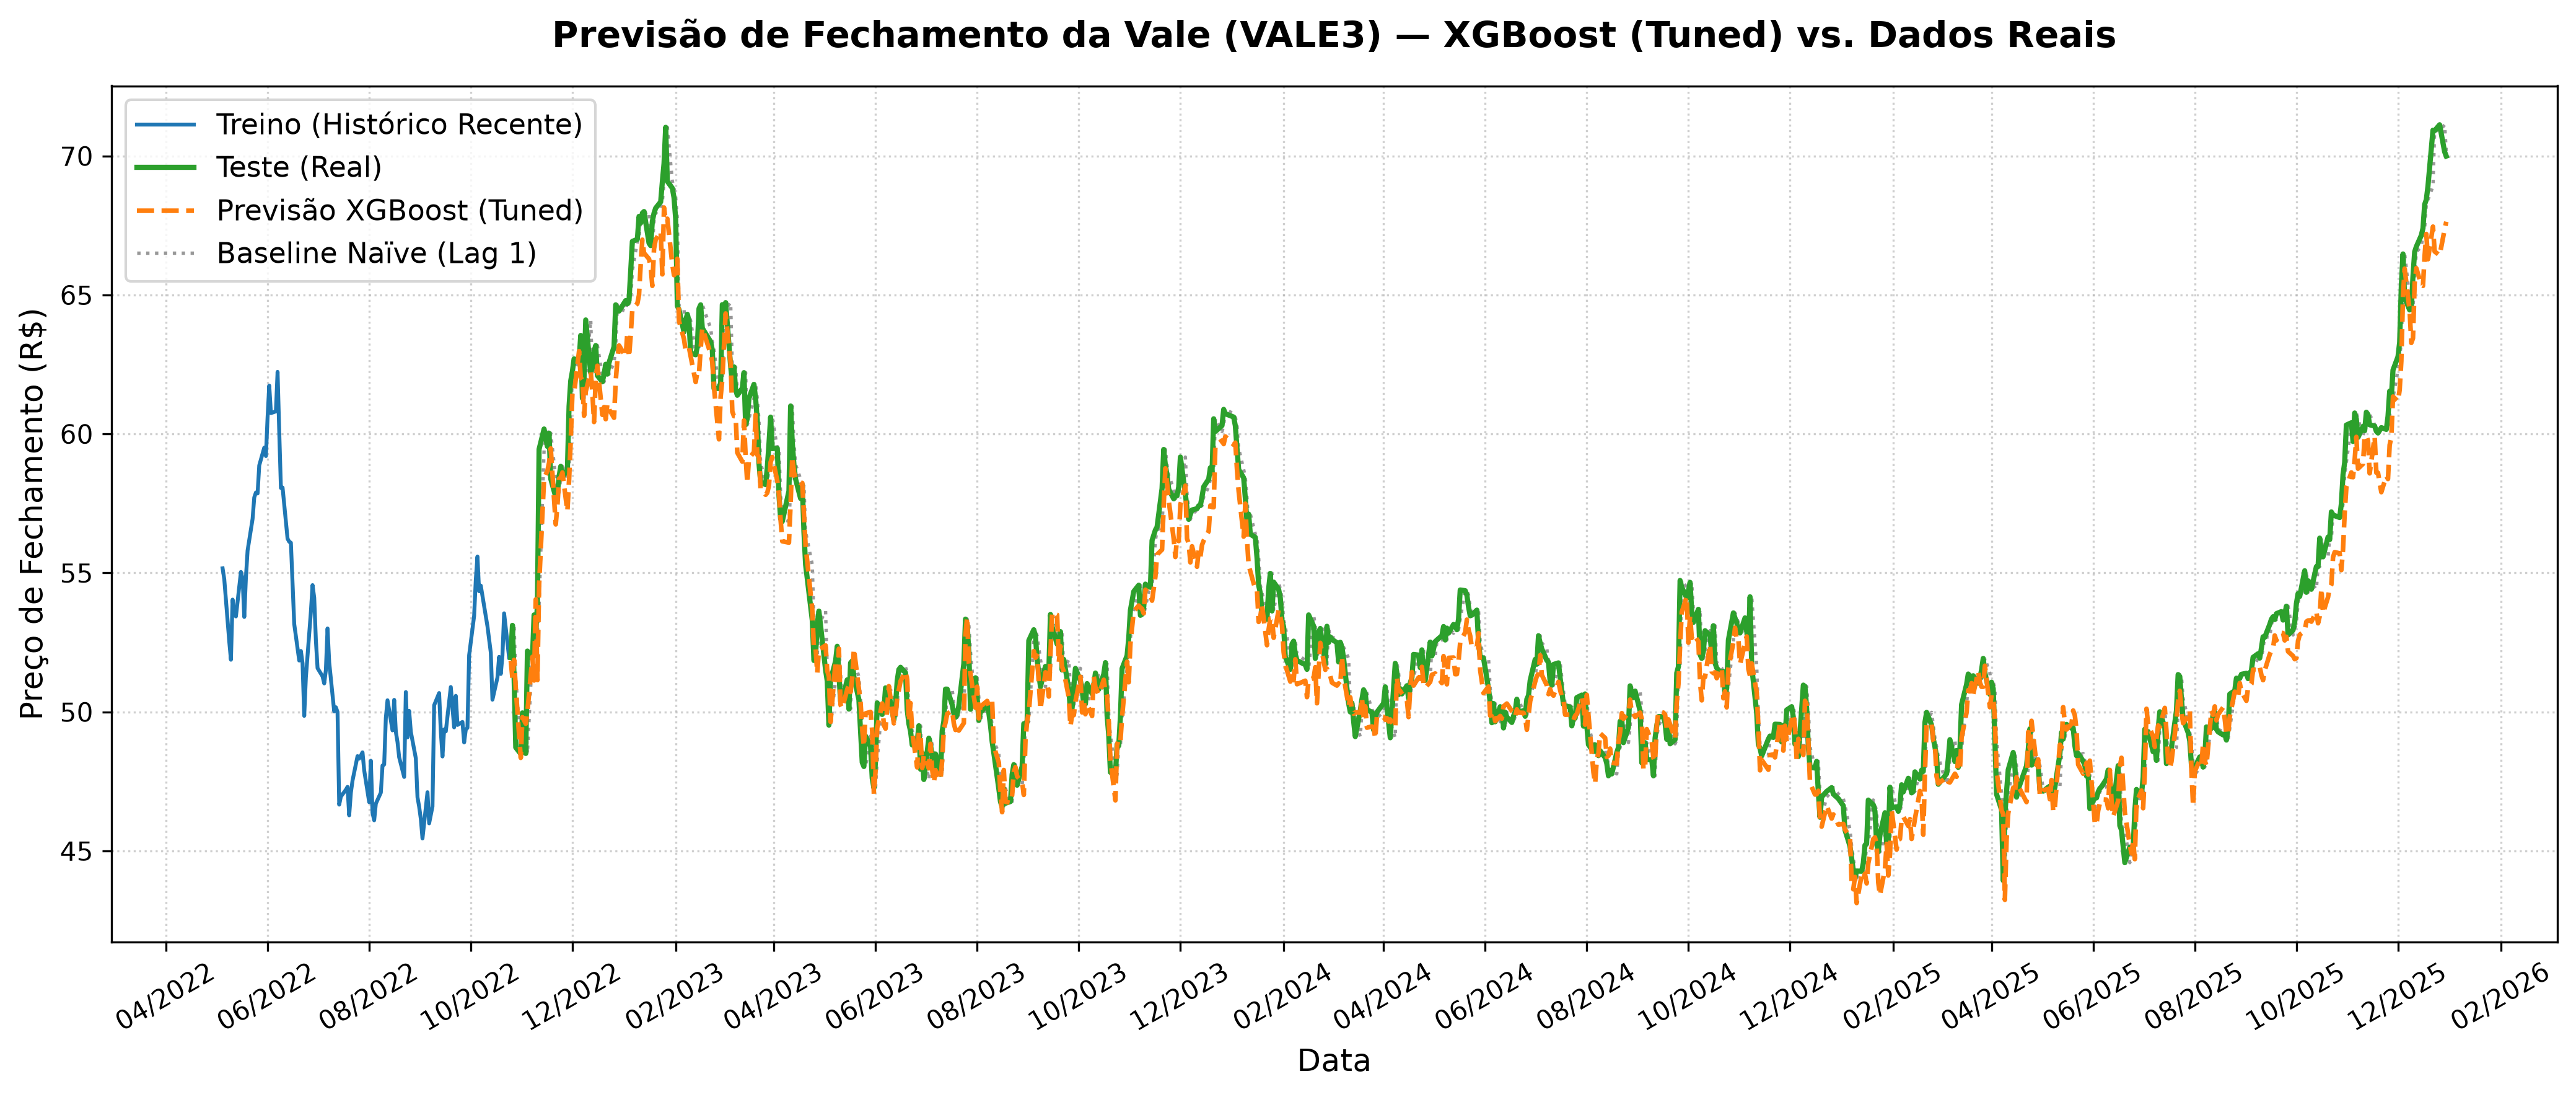

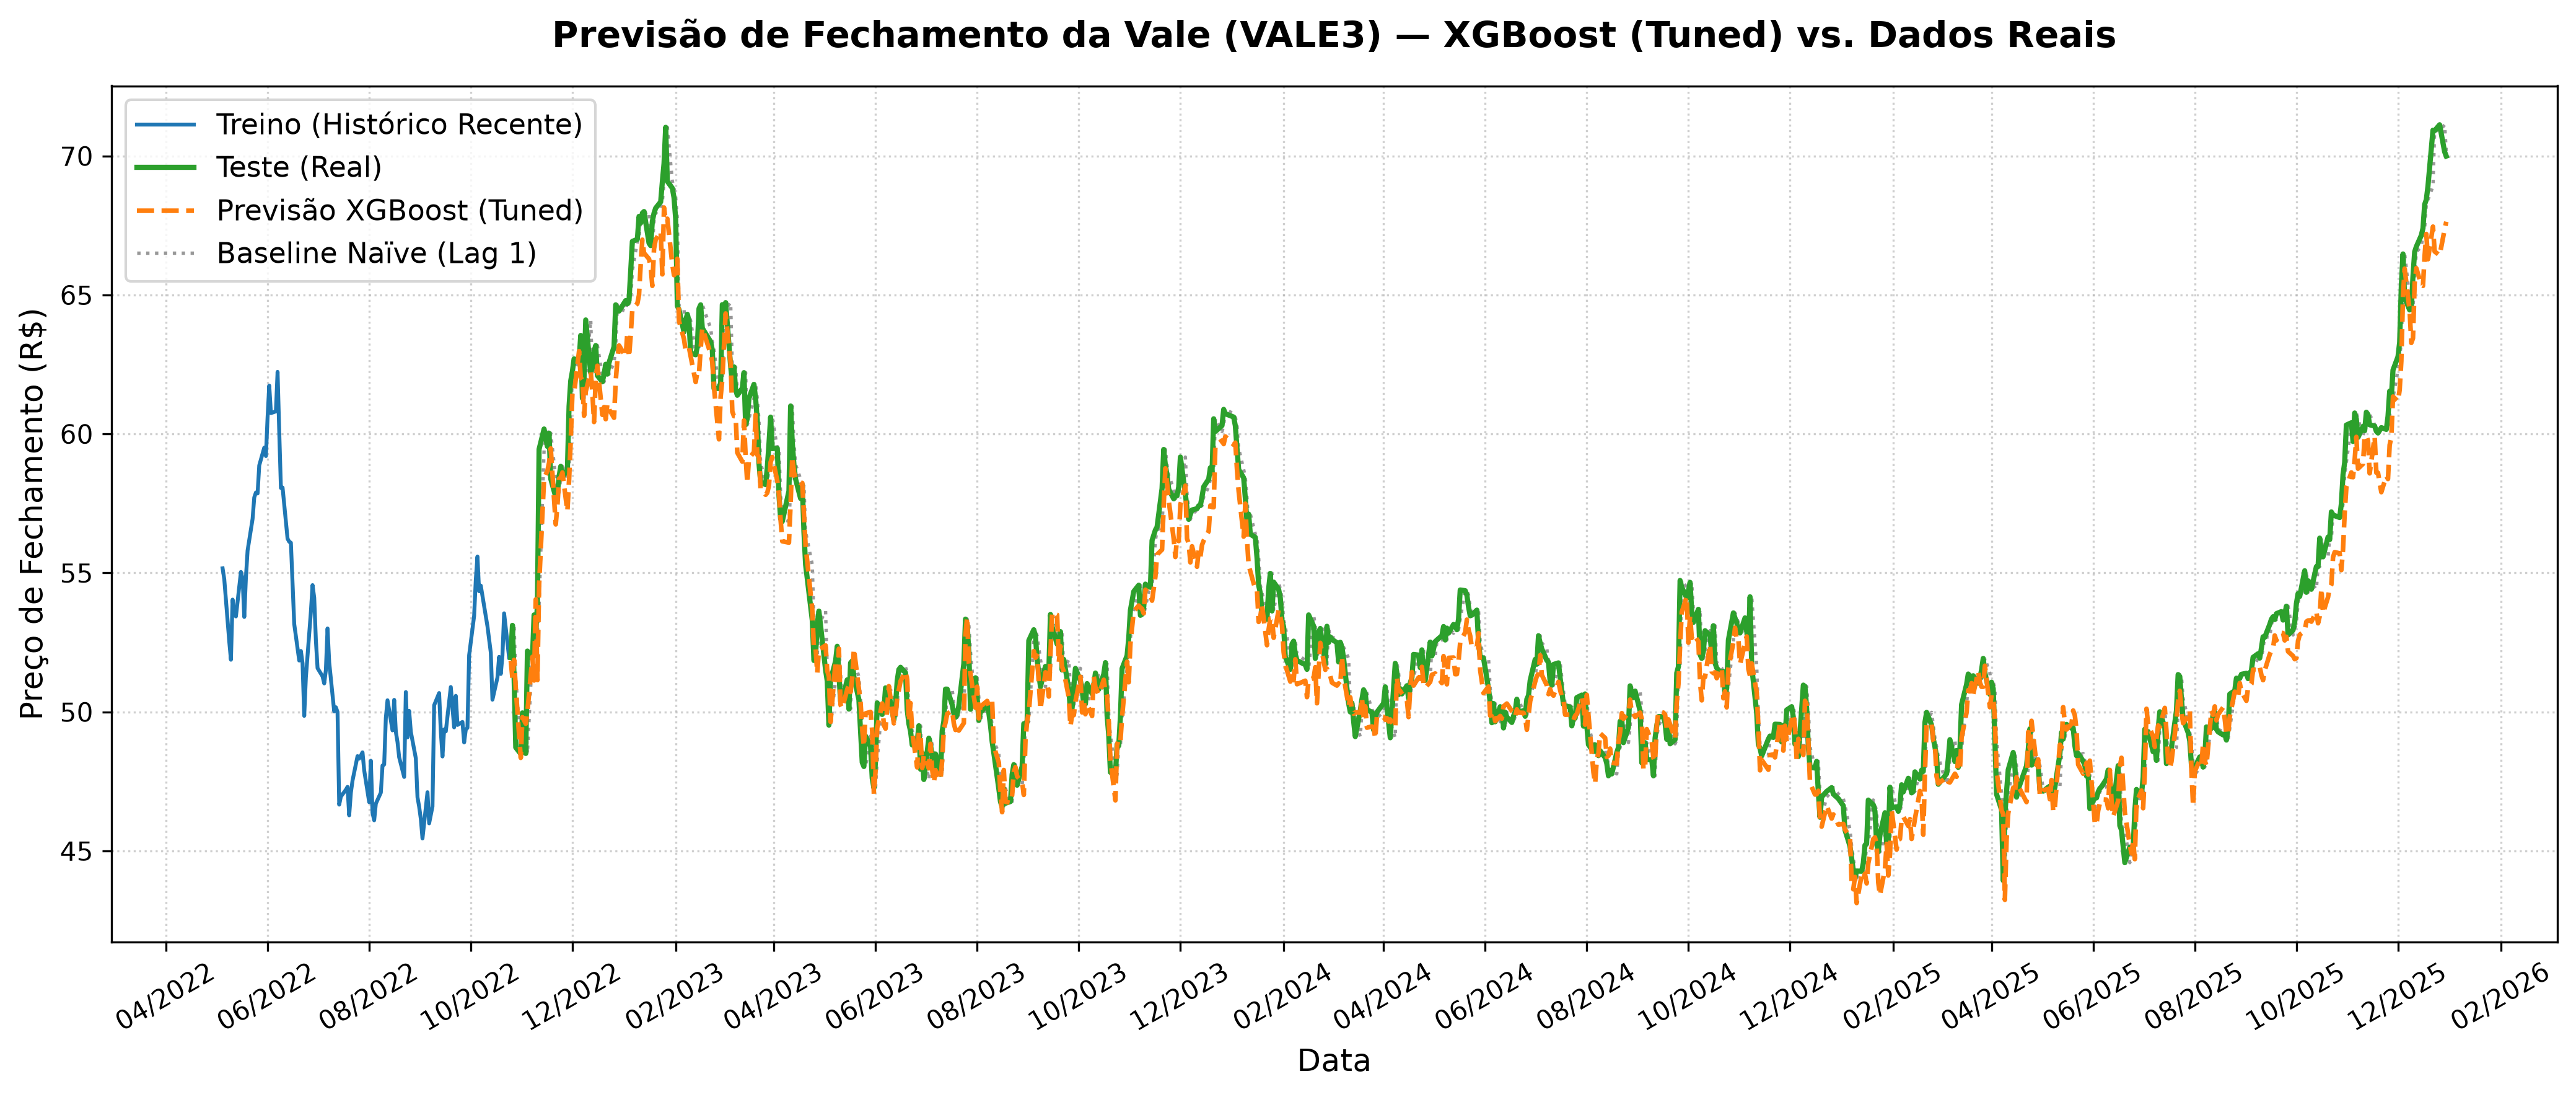

In [ ]:
res_xgb = run_xgbooster(train_vale, test_vale, "vale")
plot_forecast(
    train_vale, test_vale,
    predictions=res_xgb["predictions"],
    stock_name="vale",
    model_name="XGBoost (Tuned)",
    ticker_label="VALE3",
    company_name="Vale",
    baseline=res_xgb["ontem"],        # baseline naive (preço de ontem)
)

In [ ]:
res_lstm = run_lstm(train_vale, test_vale, "vale", max_epochs=10)
plot_forecast(train_vale, test_vale, res_lstm["predictions"], "vale",
              model_name="LSTM (Tuned)", ticker_label="VALE3",
              company_name="Vale", baseline=res_lstm["ontem"])